# Giai đoạn 6: diễn giải mô hình và phân tích lỗi
Chỉ dùng train. Importance dùng RF cuối fit trên train; phân tích lỗi dùng dự đoán out-of-fold, không dùng test.

In [1]:
# Nạp dữ liệu và RF cuối
import sys,time,json,joblib
from pathlib import Path
import numpy as np,pandas as pd
import matplotlib.pyplot as plt,seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
from sklearn.model_selection import StratifiedKFold,cross_val_predict,train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
sys.path.insert(0,str(Path('..').resolve()))
from src.data_prep import load_data,clean_data,get_feature_sets
from src.pipeline import make_pipeline
df,_=clean_data(load_data(Path('../data/RT_IOT2022'))); sets=get_feature_sets(df); features=sets['NO_SRC_PORT']; X=df.drop(columns=['Attack_type']); y=df['Attack_type']; train_idx=np.sort(np.load('../experiments/split_indices.npz')['train_idx']); Xtr=X.iloc[train_idx]; ytr=y.iloc[train_idx]; cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
params={'n_estimators':250,'max_depth':50,'min_samples_split':5,'min_samples_leaf':1,'max_features':None}
rf=make_pipeline(RandomForestClassifier(**params,random_state=42,n_jobs=-1),features,random_state=42); rf.fit(Xtr[features],ytr); print('Chỉ dùng train:',len(Xtr))

Chỉ dùng train: 94337


Mô hình được fit trên toàn bộ train để diễn giải. Đây không phải bước chọn lại mô hình.

,importance
numeric__id.resp_p,0.503199
categorical__service_mqtt,0.103061
numeric__flow_iat.min,0.097727
categorical__service_-,0.071871
numeric__fwd_header_size_tot,0.071173
numeric__fwd_URG_flag_count,0.037704
numeric__fwd_pkts_payload.min,0.030938
categorical__service_http,0.016028
numeric__fwd_iat.min,0.010646
numeric__bwd_pkts_payload.std,0.010495


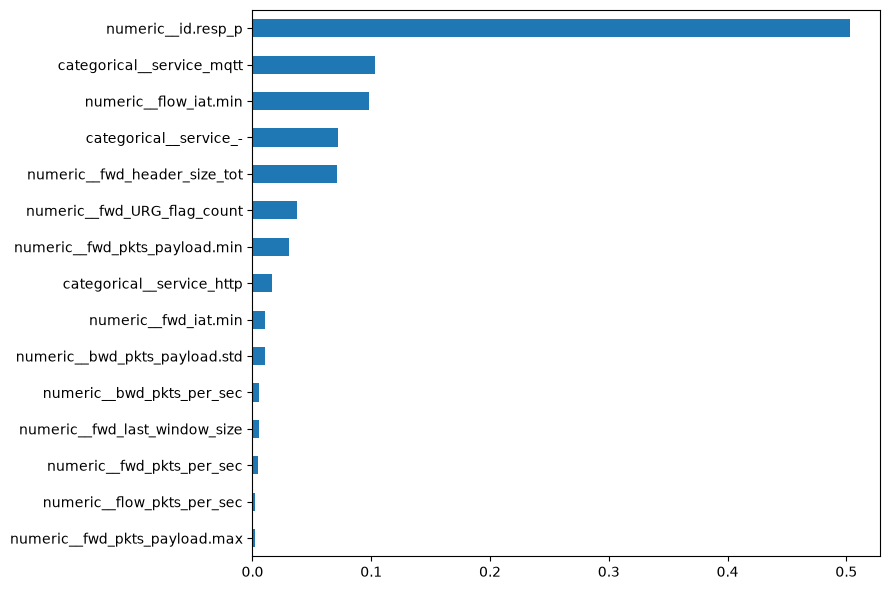

In [2]:
# Tính importance theo impurity
names=rf.named_steps['preprocess'].get_feature_names_out(); values=rf.named_steps['model'].feature_importances_; impurity=pd.Series(values,index=names).sort_values(ascending=False).head(15); display(impurity.to_frame('importance')); impurity.sort_values().plot.barh(figsize=(9,6)); plt.tight_layout(); plt.savefig('../figures/08_rf_impurity_top15.png',dpi=150); plt.show()

Importance impurity cho biết mức giảm độ hỗn tạp mà RF dùng khi chia cây. Các cột one-hot có tiền tố `categorical__`.

Thời gian permutation: 151.04s


,mean_decrease_f1
id.resp_p,0.649587
service,0.364400
fwd_header_size_tot,0.276208
fwd_URG_flag_count,0.116429
bwd_pkts_payload.std,0.115130
flow_iat.min,0.098807
fwd_pkts_payload.min,0.087668
proto,0.068901
fwd_last_window_size,0.037766
fwd_iat.min,0.009762


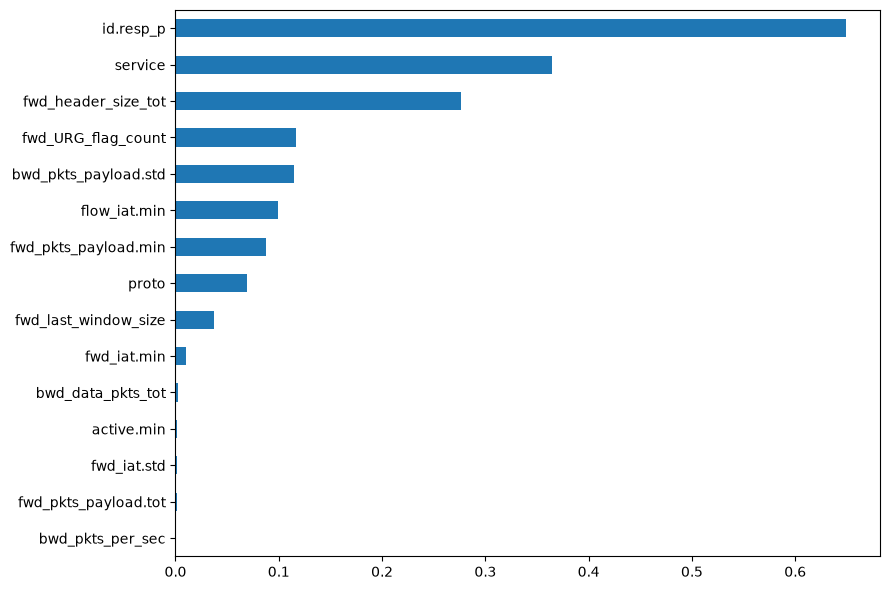

In [3]:
# Đo permutation importance trên một validation split của train
a,b=train_test_split(np.arange(len(Xtr)),test_size=.2,stratify=ytr,random_state=42); start=time.perf_counter(); perm=permutation_importance(rf,Xtr.iloc[b][features],ytr.iloc[b],scoring='f1_macro',n_repeats=3,n_jobs=-1,random_state=42); seconds=time.perf_counter()-start; print(f'Thời gian permutation: {seconds:.2f}s'); perm_table=pd.Series(perm.importances_mean,index=features).sort_values(ascending=False).head(15); display(perm_table.to_frame('mean_decrease_f1')); perm_table.sort_values().plot.barh(figsize=(9,6)); plt.tight_layout(); plt.savefig('../figures/09_rf_permutation_top15.png',dpi=150); plt.show()

Permutation importance đo mức giảm Macro-F1 khi xáo trộn từng cột trên 20% validation của train. Không dùng test.

In [4]:
# So sánh top và nhóm tương quan cao
corr=Xtr.select_dtypes('number').corr(); pairs=[]
for i,c1 in enumerate(corr.columns):
    for c2 in corr.columns[i+1:]:
        if abs(corr.loc[c1,c2])>.95: pairs.append({'feature_1':c1,'feature_2':c2,'r':corr.loc[c1,c2]})
high_corr=pd.DataFrame(pairs); high_corr.to_csv('../experiments/high_corr_pairs.csv',index=False); print('Đặc trưng tương quan cao:',len(high_corr)); display(high_corr.head(20)); print('Impurity top:',impurity.index.tolist()); print('Permutation top:',perm_table.index.tolist())

Đặc trưng tương quan cao: 52


,feature_1,feature_2,r
0,flow_duration,fwd_iat.tot,0.999667
1,flow_duration,flow_iat.tot,1.000000
2,flow_duration,idle.tot,0.996698
3,bwd_pkts_tot,bwd_data_pkts_tot,0.993526
4,bwd_pkts_tot,bwd_header_size_tot,0.985162
5,bwd_pkts_tot,flow_ACK_flag_count,0.961095
6,bwd_pkts_tot,bwd_pkts_payload.tot,0.978673
7,bwd_pkts_tot,flow_pkts_payload.tot,0.986294
8,bwd_data_pkts_tot,bwd_header_size_tot,0.977778
9,bwd_data_pkts_tot,bwd_pkts_payload.tot,0.993467


Impurity top: ['numeric__id.resp_p', 'categorical__service_mqtt', 'numeric__flow_iat.min', 'categorical__service_-', 'numeric__fwd_header_size_tot', 'numeric__fwd_URG_flag_count', 'numeric__fwd_pkts_payload.min', 'categorical__service_http', 'numeric__fwd_iat.min', 'numeric__bwd_pkts_payload.std', 'numeric__bwd_pkts_per_sec', 'numeric__fwd_last_window_size', 'numeric__fwd_pkts_per_sec', 'numeric__flow_pkts_per_sec', 'numeric__fwd_pkts_payload.max']
Permutation top: ['id.resp_p', 'service', 'fwd_header_size_tot', 'fwd_URG_flag_count', 'bwd_pkts_payload.std', 'flow_iat.min', 'fwd_pkts_payload.min', 'proto', 'fwd_last_window_size', 'fwd_iat.min', 'bwd_data_pkts_tot', 'active.min', 'fwd_iat.std', 'fwd_pkts_payload.tot', 'bwd_pkts_per_sec']


Khi nhiều đặc trưng tương quan cao, importance có thể bị chia sẻ: một cột nhận điểm cao hơn không có nghĩa cột còn lại không hữu ích.

|--- id.resp_p <= 21.50
|   |--- fwd_pkts_payload.min <= 114.50
|   |   |--- fwd_PSH_flag_count <= 0.50
|   |   |   |--- proto_udp <= 0.50
|   |   |   |   |--- class: NMAP_OS_DETECTION
|   |   |   |--- proto_udp >  0.50
|   |   |   |   |--- class: NMAP_UDP_SCAN
|   |   |--- fwd_PSH_flag_count >  0.50
|   |   |   |--- class: NMAP_XMAS_TREE_SCAN
|   |--- fwd_pkts_payload.min >  114.50
|   |   |--- class: DOS_SYN_Hping
|--- id.resp_p >  21.50
|   |--- flow_iat.min <= 35.52
|   |   |--- service_- <= 0.50
|   |   |   |--- service_http <= 0.50
|   |   |   |   |--- class: ARP_poisioning
|   |   |   |--- service_http >  0.50
|   |   |   |   |--- class: DDOS_Slowloris
|   |   |--- service_- >  0.50
|   |   |   |--- fwd_header_size_tot <= 14.00
|   |   |   |   |--- class: NMAP_UDP_SCAN
|   |   |   |--- fwd_header_size_tot >  14.00
|   |   |   |   |--- class: NMAP_OS_DETECTION
|   |--- flow_iat.min >  35.52
|   |   |--- service_mqtt <= 0.50
|   |   |   |--- bwd_pkts_payload.std <= 22.27
|   |   |

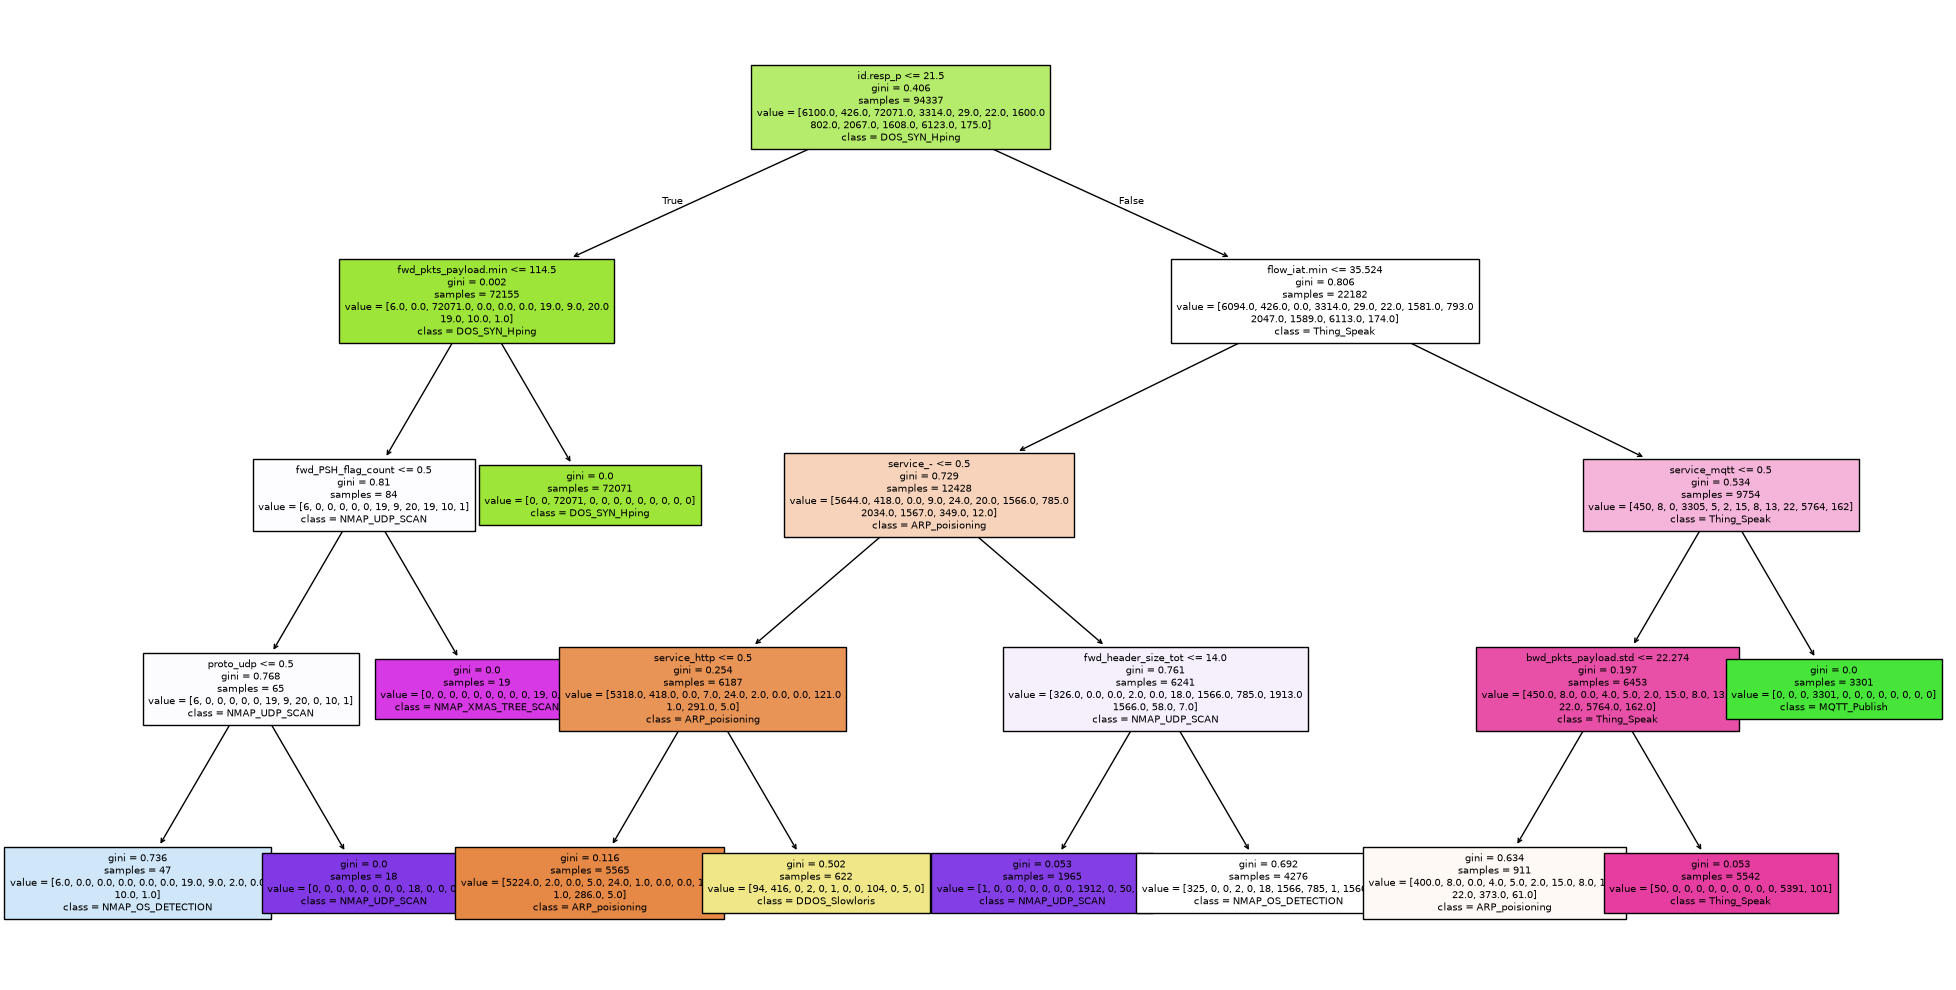

Đây là mô hình giải thích, không phải mô hình cuối.


In [5]:
# Cây nông chỉ để giải thích
small=DecisionTreeClassifier(max_depth=4,random_state=42); small.fit(pd.get_dummies(Xtr[features],columns=['proto','service']),ytr); print(export_text(small,feature_names=list(pd.get_dummies(Xtr[features],columns=['proto','service']).columns))); plt.figure(figsize=(20,10)); plot_tree(small,feature_names=list(pd.get_dummies(Xtr[features],columns=['proto','service']).columns),class_names=sorted(ytr.unique()),filled=True,max_depth=4,fontsize=7); plt.tight_layout(); plt.savefig('../figures/10_shallow_tree.png',dpi=150); plt.show(); print('Đây là mô hình giải thích, không phải mô hình cuối.')

Cây sâu tối đa 4 giúp trình bày luật dễ hiểu. Nó chỉ phục vụ diễn giải, không thay thế RF cuối.

In [6]:
# Dự đoán OOF một lần và lưu cache
oof_path=Path('../experiments/rf_oof_train.npy')
if oof_path.exists():
    oof=np.load(oof_path,allow_pickle=True)
else:
    start_oof=time.perf_counter(); oof=cross_val_predict(rf,Xtr[features],ytr,cv=cv,n_jobs=-1); np.save(oof_path,oof); print(f'Đã tính và lưu OOF sau {time.perf_counter()-start_oof:.2f} giây.')
true=ytr.to_numpy(); top_features=impurity.index[:10].tolist(); raw_features=[n.split('__')[-1] for n in top_features if n.split('__')[-1] in Xtr.columns and n.split('__')[-1] not in {'proto','service'}]; raw_features=(raw_features+[c for c in features if c not in raw_features and c not in {'proto','service'}])[:10]; normal={'Thing_Speak','MQTT_Publish','Wipro_bulb'}
pairs_to_check=[('ARP_poisioning','Thing_Speak'),('Thing_Speak','ARP_poisioning'),('DDOS_Slowloris','NMAP_UDP_SCAN'),('NMAP_UDP_SCAN','DDOS_Slowloris'),('Wipro_bulb','Thing_Speak')]; rows=[]
for actual,pred in pairs_to_check:
    for label,mask in [('true_correct',(true==actual)&(oof==actual)),('misclassified',(true==actual)&(oof==pred)),('target_correct',(true==pred)&(oof==pred))]:
        if mask.any(): rows.append({'actual':actual,'predicted':pred,'group':label,**Xtr.iloc[np.flatnonzero(mask)][raw_features].median(numeric_only=True).to_dict()})
display(pd.DataFrame(rows))
error_df=pd.DataFrame({'true':true,'pred':oof}); error_positions=np.flatnonzero(true!=oof)
row_keys=Xtr[features].astype(str).agg('|'.join,axis=1).to_numpy(); group_labels=pd.DataFrame({'key':row_keys,'label':ytr.to_numpy()}).groupby('key')['label'].nunique(); collisions=sum(group_labels.get(row_keys[pos],1)>1 for pos in error_positions)
print('Mẫu bị nhầm có vector đặc trưng trùng mẫu khác nhãn:',int(collisions))


Đã tính và lưu OOF sau 244.07 giây.


,actual,predicted,group,id.resp_p,flow_iat.min,fwd_header_size_tot,fwd_URG_flag_count,fwd_pkts_payload.min,fwd_iat.min,bwd_pkts_payload.std,flow_duration,fwd_pkts_tot,bwd_pkts_tot
0,ARP_poisioning,Thing_Speak,true_correct,443.0,5.006790,16.0,0.0,43.0,6.914139,11.313708,0.000648,2.0,2.0
1,ARP_poisioning,Thing_Speak,misclassified,53.0,41949.033737,8.0,0.0,44.0,0.000000,0.000000,0.076483,1.0,1.0
2,ARP_poisioning,Thing_Speak,target_correct,80.0,193.119049,16.0,0.0,32.0,230.073929,36.769553,0.139521,2.0,2.0
3,Thing_Speak,ARP_poisioning,true_correct,80.0,193.119049,16.0,0.0,32.0,230.073929,36.769553,0.139521,2.0,2.0
4,Thing_Speak,ARP_poisioning,misclassified,53.0,817.060471,16.0,0.0,43.0,91.552735,0.000000,0.106150,2.0,1.0
5,Thing_Speak,ARP_poisioning,target_correct,443.0,5.006790,16.0,0.0,43.0,6.914139,11.313708,0.000648,2.0,2.0
6,DDOS_Slowloris,NMAP_UDP_SCAN,true_correct,80.0,5.006790,200.0,0.0,0.0,13.828278,0.000000,21.229430,6.0,4.0
7,DDOS_Slowloris,NMAP_UDP_SCAN,misclassified,80.0,20.027161,260.0,0.0,0.0,20.027161,0.000000,0.000512,8.0,0.0
8,DDOS_Slowloris,NMAP_UDP_SCAN,target_correct,19374.0,0.000000,8.0,0.0,0.0,0.000000,0.000000,0.000000,1.0,0.0
9,NMAP_UDP_SCAN,DDOS_Slowloris,true_correct,19374.0,0.000000,8.0,0.0,0.0,0.000000,0.000000,0.000000,1.0,0.0


Mẫu bị nhầm có vector đặc trưng trùng mẫu khác nhãn: 8


Phân tích lỗi dùng OOF trên train. Trung vị được in cho nhóm đúng, nhóm bị nhầm và nhóm đích đúng; số collision chỉ là mô tả, không xóa dữ liệu.

## Kết luận RQ3
Dựa trên bảng OOF và hai danh sách top 15, nhóm sẽ ghi cụ thể các cặp nhầm nhiều nhất, đặc trưng đóng góp cao nhất và khả năng nguyên nhân như đặc trưng tương quan hoặc các vector trùng khác nhãn. Các con số phải lấy từ output thực tế của notebook.

In [7]:
# Lưu RF cuối, metadata và sample flows
Path('../models').mkdir(exist_ok=True); joblib.dump(rf,'../models/final_rf.joblib',compress=3); size=Path('../models/final_rf.joblib').stat().st_size/1024**2; print(f'Model size={size:.2f} MB')
if size>90: print('CẢNH BÁO: model lớn hơn 90 MB; thêm models/ vào .gitignore trước khi commit.')
sample=df.iloc[train_idx].groupby('Attack_type',group_keys=False).head(2); sample[features+['Attack_type']].to_csv('../demo_sample_flows.csv',index=False); meta={'features':features,'labels':sorted(y.unique()),'params':params,'trained_at':pd.Timestamp.now().isoformat(),'cv_macro_f1':0.957256,'test_macro_f1':0.9813,'normal_labels':sorted(normal),'task':'RF cuối NO_SRC_PORT'}; Path('../models/metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8'); loaded=joblib.load('../models/final_rf.joblib'); print(pd.DataFrame({'true':sample.Attack_type,'pred':loaded.predict(sample[features])}))

Model size=2.55 MB
                              true                 pred
0                     MQTT_Publish         MQTT_Publish
1                     MQTT_Publish         MQTT_Publish
4142                   Thing_Speak          Thing_Speak
4144                   Thing_Speak          Thing_Speak
11796                   Wipro_bulb           Wipro_bulb
11797                   Wipro_bulb           Wipro_bulb
12015               ARP_poisioning       ARP_poisioning
12016               ARP_poisioning       ARP_poisioning
19641               DDOS_Slowloris       DDOS_Slowloris
19644               DDOS_Slowloris       DDOS_Slowloris
20173                DOS_SYN_Hping        DOS_SYN_Hping
20174                DOS_SYN_Hping        DOS_SYN_Hping
110262  Metasploit_Brute_Force_SSH       ARP_poisioning
110263  Metasploit_Brute_Force_SSH       ARP_poisioning
110298               NMAP_FIN_SCAN        NMAP_FIN_SCAN
110299               NMAP_FIN_SCAN        NMAP_FIN_SCAN
110326           NMAP_OS_DETE